<a href="https://colab.research.google.com/github/natsakh/IAD/blob/main/Pr_8/8_6_HF_DINOv2_image_similarity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DINOv2: які зображення схожі між собою?
**Oxford-IIIT Pet → 10 фотографій → вектори ознак → евклідівські відстані → найближча та найдальша пари.**

Ми використовуємо **DINOv2 Small** — представника сімейства DINO — через Hugging Face. Модель уже навчена; тут немає навчання або класифікатора. Мітки порід використовуємо лише для вибору фото та підписів.

Перший запуск завантажує весь архів фотографій Oxford-IIIT Pet (близько 800 МБ) і ваги моделі; наступні запуски в тому самому середовищі використовують кеш.

## 1. Бібліотеки


In [11]:
#!pip install transformers

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import torchvision
import transformers
from torchvision.datasets import OxfordIIITPet
from transformers import AutoImageProcessor, AutoModel
from IPython.display import display

SEED = 42
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Пристрій:", device)
print("PyTorch:", torch.__version__)
print("torchvision:", torchvision.__version__)
print("Transformers:", transformers.__version__)

Пристрій: cuda
PyTorch: 2.11.0+cu130
torchvision: 0.26.0+cu130
Transformers: 5.20.2


## 2. Завантаження фотографій
Oxford-IIIT Pet містить котів і собак 37 порід. Зображення мають різні розміри; не зменшуємо їх вручну до 32 × 32.

Обираємо по два фото з п’яти порід: **сіамський кіт, перський кіт, мопс, бігль, самоїд**. Фіксоване зерно генератора робить вибір повторюваним.

In [3]:
dataset = OxfordIIITPet(
    root="./data", split="test", target_types="category", download=True
)
print("Кількість зображень у тестовій частині:", len(dataset))
print("Класи:", dataset.classes)

100%|██████████| 792M/792M [00:32<00:00, 24.3MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 11.3MB/s]


Кількість зображень у тестовій частині: 3669
Класи: ['Abyssinian', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle', 'Bengal', 'Birman', 'Bombay', 'Boxer', 'British Shorthair', 'Chihuahua', 'Egyptian Mau', 'English Cocker Spaniel', 'English Setter', 'German Shorthaired', 'Great Pyrenees', 'Havanese', 'Japanese Chin', 'Keeshond', 'Leonberger', 'Maine Coon', 'Miniature Pinscher', 'Newfoundland', 'Persian', 'Pomeranian', 'Pug', 'Ragdoll', 'Russian Blue', 'Saint Bernard', 'Samoyed', 'Scottish Terrier', 'Shiba Inu', 'Siamese', 'Sphynx', 'Staffordshire Bull Terrier', 'Wheaten Terrier', 'Yorkshire Terrier']


In [4]:
# Читаємо офіційний список міток, щоб не відкривати всі фото під час відбору.
from pathlib import Path
annotation_file = Path("./data/oxford-iiit-pet/annotations/test.txt")
rows = [line.split() for line in annotation_file.read_text().splitlines()
        if line.strip() and not line.startswith("#")]
# У файлі класи нумеруються з 1, у torchvision — з 0.
all_labels = np.array([int(row[1]) - 1 for row in rows])
assert len(all_labels) == len(dataset)

chosen_breeds = ["Siamese", "Persian", "Pug", "Beagle", "Samoyed"]
class_to_id = {name.lower(): i for i, name in enumerate(dataset.classes)}
selected_indices = []
for breed in chosen_breeds:
    candidates = np.flatnonzero(all_labels == class_to_id[breed.lower()])
    selected_indices.extend(rng.choice(candidates, size=2, replace=False).tolist())

images, labels = [], []
for idx in selected_indices:
    image, label = dataset[idx]
    assert label == all_labels[idx]  # Перевіряємо відповідність індексів і міток.
    images.append(image.convert("RGB"))
    labels.append(label)

names = [dataset.classes[label] for label in labels]
print("Індекси вибраних фото:", selected_indices)
print("Розміри оригіналів:", [image.size for image in images])

Індекси вибраних фото: [3188, 3257, 2324, 2380, 2550, 2489, 407, 450, 2953, 2957]
Розміри оригіналів: [(300, 253), (335, 500), (500, 380), (500, 353), (500, 333), (500, 374), (500, 333), (334, 500), (333, 500), (500, 357)]


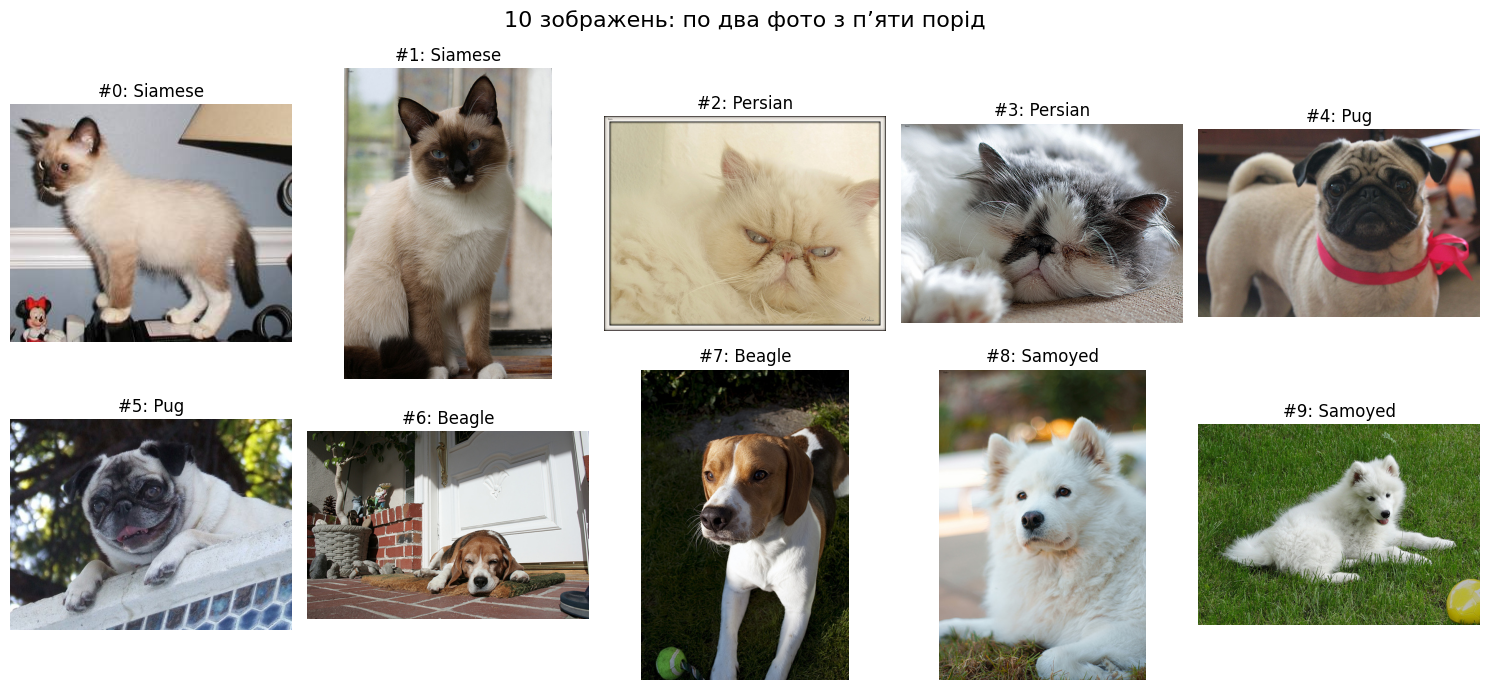

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(15, 7))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i])
    ax.set_title(f"#{i}: {names[i]}")
    ax.axis("off")
fig.suptitle("10 зображень: по два фото з п’яти порід", fontsize=16)
plt.tight_layout()
plt.show()

## 3. DINOv2 як екстрактор ознак
`AutoImageProcessor` виконує потрібну моделі підготовку зображень: зміну розміру, центральне обрізання й нормування пікселів. Через обрізання модель може бачити не весь оригінал.

`AutoModel` повертає ознаки, а не назви класів. DINOv2 розбиває зображення на патчі. Крім ознак патчів, вихід містить **CLS-токен**, який використаємо як один вектор для всього зображення:

```python
outputs.last_hidden_state[:, 0, :]
```
Для DINOv2 Small довжина такого вектора — 384. Координати вектора — навчені ознаки, а не ймовірності класів.

In [ ]:
MODEL_ID = "facebook/dinov2-small"
processor = AutoImageProcessor.from_pretrained(MODEL_ID, use_fast=False)
model = AutoModel.from_pretrained(MODEL_ID).to(device)
model.eval()  # Режим оцінювання: модель не навчається.

feature_batches = []
BATCH_SIZE = 5
with torch.inference_mode():  # Не обчислюємо градієнти.
    for start in range(0, len(images), BATCH_SIZE):
        inputs = processor(images=images[start:start + BATCH_SIZE], return_tensors="pt")
        inputs = {key: value.to(device) for key, value in inputs.items()}
        outputs = model(**inputs)
        cls_features = outputs.last_hidden_state[:, 0, :]
        feature_batches.append(cls_features.cpu())

features = torch.cat(feature_batches, dim=0)
print("Розмір матриці ознак:", tuple(features.shape))
print("Норми початкових векторів:", features.norm(dim=1).numpy().round(3))

## 4. Нормування та відстані
LayerNorm усередині моделі **не гарантує одиничної L2-норми вихідного вектора**. Нормуємо кожен вектор окремо:

$$\hat{\mathbf z}_i=\frac{\mathbf z_i}{\|\mathbf z_i\|_2}.$$

Порівнюємо зображення за евклідівською відстанню між нормованими ознаками:

$$d_{ij}=\|\hat{\mathbf z}_i-\hat{\mathbf z}_j\|_2.$$

**Менша відстань → більша схожість за ознаками DINOv2.** Для одиничних векторів $d_{ij}^2=2(1-s_{ij})$, де $s_{ij}$ — косинусна подібність. Отже, ці два способи дають однакове ранжування пар. Відстань лежить у межах від 0 до 2.

Мітки порід у розрахунках не використовуються.

In [7]:
normalized_features = F.normalize(features, p=2, dim=1)
distances = torch.cdist(normalized_features, normalized_features, p=2).numpy()
np.fill_diagonal(distances, 0.0)
print("Норми після нормування:", normalized_features.norm(dim=1).numpy().round(4))

# Перевірка математичного зв’язку з косинусною подібністю.
cosine_similarity = (normalized_features @ normalized_features.T).numpy()
assert np.allclose(distances ** 2, 2 * (1 - cosine_similarity), atol=1e-5)
assert np.allclose(distances, distances.T, atol=1e-6)

Норми після нормування: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## 5. Матриця попарних відстаней
Кожна клітинка — відстань між двома фото. Нулі на діагоналі відповідають порівнянню зображення із самим собою. Матриця симетрична. На цій палітрі темніші клітинки означають менші відстані.

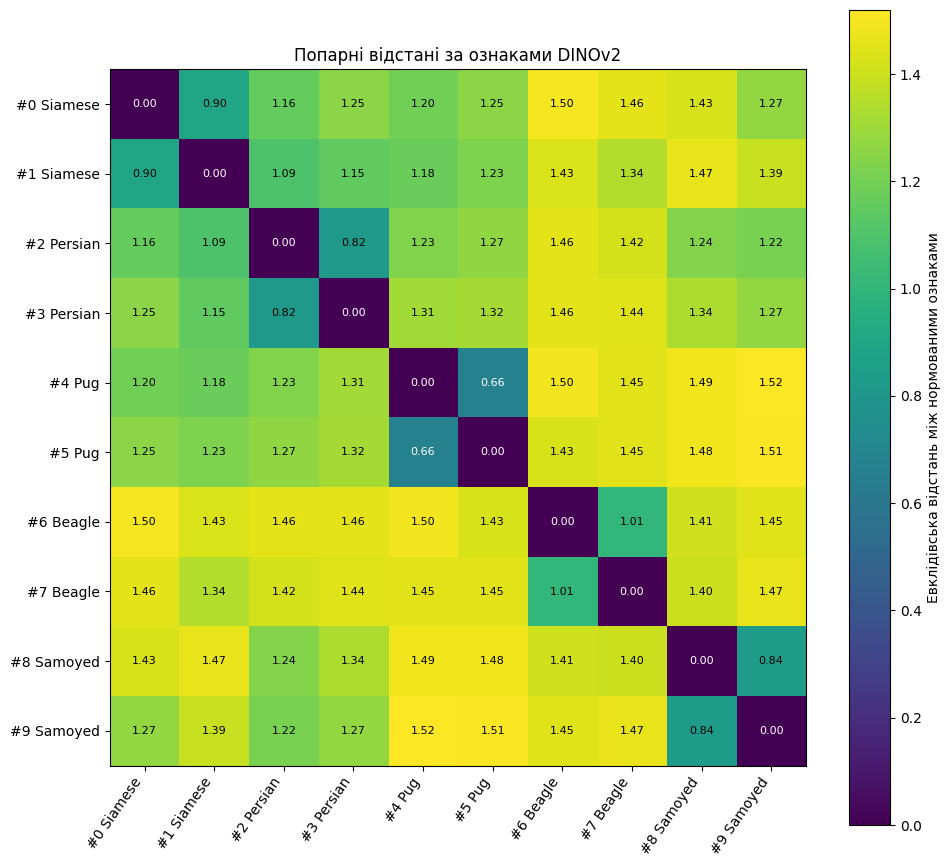

In [8]:
tick_labels = [f"#{i} {name}" for i, name in enumerate(names)]
fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(distances, cmap="viridis", vmin=0, vmax=max(float(distances.max()), 1e-6))
ax.set_xticks(range(len(images)), tick_labels, rotation=55, ha="right")
ax.set_yticks(range(len(images)), tick_labels)
for i in range(len(images)):
    for j in range(len(images)):
        color = "white" if distances[i, j] < distances.max() * 0.5 else "black"
        ax.text(j, i, f"{distances[i, j]:.2f}", ha="center", va="center", color=color, fontsize=8)
fig.colorbar(im, ax=ax, label="Евклідівська відстань між нормованими ознаками")
ax.set_title("Попарні відстані за ознаками DINOv2")
plt.tight_layout()
plt.show()

## 6. Найближча та найдальша пари


In [9]:
row_ids, col_ids = np.triu_indices(len(images), k=1)
pair_distances = distances[row_ids, col_ids]
nearest_pos = int(np.argmin(pair_distances))
farthest_pos = int(np.argmax(pair_distances))
nearest_pair = (int(row_ids[nearest_pos]), int(col_ids[nearest_pos]))
farthest_pair = (int(row_ids[farthest_pos]), int(col_ids[farthest_pos]))
print("Кількість унікальних пар:", len(pair_distances))

pairs_table = pd.DataFrame({
    "Фото 1": row_ids, "Фото 2": col_ids,
    "Порода 1": [names[i] for i in row_ids],
    "Порода 2": [names[j] for j in col_ids],
    "Відстань": pair_distances,
}).sort_values("Відстань").reset_index(drop=True)
display(pairs_table.iloc[[0, -1]].round(4))

Кількість унікальних пар: 45


,Фото 1,Фото 2,Порода 1,Порода 2,Відстань
0,4,5,Pug,Pug,0.6649
44,4,9,Pug,Samoyed,1.5196


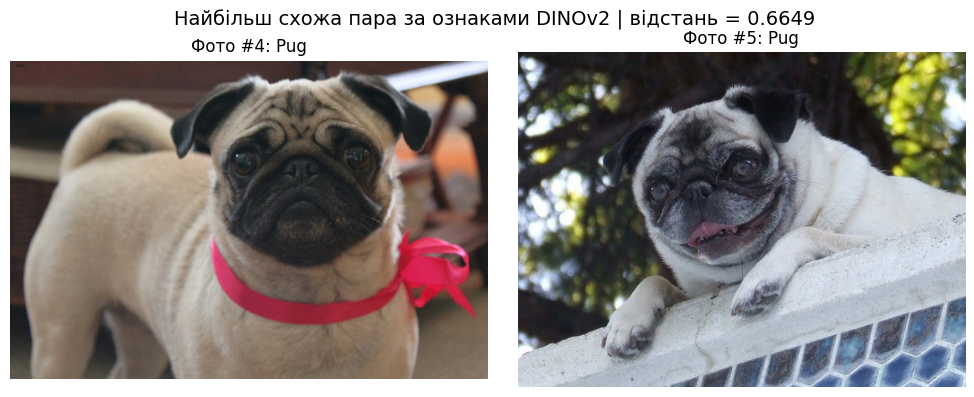

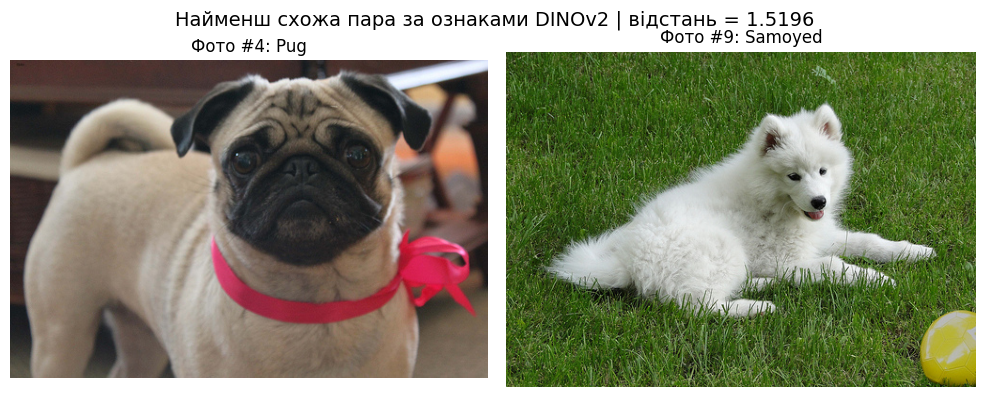

In [10]:
def show_pair(pair, title):
    i, j = pair
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for ax, idx in zip(axes, pair):
        ax.imshow(images[idx])
        ax.set_title(f"Фото #{idx}: {names[idx]}")
        ax.axis("off")
    fig.suptitle(f"{title} | відстань = {distances[i, j]:.4f}", fontsize=14)
    plt.tight_layout()
    plt.show()

show_pair(nearest_pair, "Найбільш схожа пара за ознаками DINOv2")
show_pair(farthest_pair, "Найменш схожа пара за ознаками DINOv2")



## Джерела
- [Oxford-IIIT Pet: офіційна сторінка](https://www.robots.ox.ac.uk/~vgg/data/pets/)
- [OxfordIIITPet у torchvision](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.OxfordIIITPet.html)
- [DINOv2 Small на Hugging Face](https://huggingface.co/facebook/dinov2-small)
- [DINOv2: офіційний репозиторій](https://github.com/facebookresearch/dinov2)